# Reproducing Figure 3: the vitamin B12 counterfactual

This notebook reproduces this paper's Figure 3: (a) how much of each
country's minimum land requirement is spent on vitamin B12 alone
(comparing the full model against the same model with B12 assumed
supplied off-farm), and (b) the same off-farm-supply trick repeated for
every nutrient, one at a time, to show B12 is a genuine outlier in the
model's own output rather than an assumption.

Self-contained: only `functions.py`, `functions_supply.py`,
`global_var.py`, and `data/` in this repository are needed. Runtime is a
few minutes (~18 countries x ~17 nutrients, one LP solve each).

For interactive exploration - including a per-country drill-down into
which specific products the model leans on for B12 - see the companion
dashboard: **[dashboard](https://foodsec-dashboard.politerock-163c694a.switzerlandnorth.azurecontainerapps.io)**


## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

import functions as F
import functions_supply as FS
import global_var as GVARS

EXCLUDED_COUNTRIES = {"South Africa"}

## 2. Reference tables, crop yields, animal land caps

Identical setup to `reproduce_figure2.ipynb` - see that notebook for
details on each step.

In [2]:
df_composition = pd.read_csv("data/crop_composition_table.csv")
df_composition = df_composition.dropna(subset=["crop"]).set_index("crop")
df_composition = df_composition.fillna(0).replace(" ", 0).astype(float)
df_composition *= 10
df_composition["edible.prop"] /= 10

df_animal = pd.read_excel("data/animal_composition_table_with_carrying_capacity.xlsx", sheet_name="production ha-1")
df_animal = df_animal.set_index("animal").drop(columns=["fat"])

df_dri = pd.read_excel("data/food_comp_DRI.xlsx", sheet_name="dietary reference intake")
dri = (df_dri.drop(columns=["fat", "age group", "gender"]).iloc[0] * 365).values

df_yield = pd.read_csv("data/original/FAOSTAT_data_en_3-25-2026.csv")
df_yield = df_yield[["Item", "Year", "Area", "Value"]]
df_yield = df_yield.rename(columns={"Item": "crop", "Year": "year", "Area": "country", "Value": "yield_per_ha"})
df_yield["crop"] = df_yield["crop"].apply(lambda x: GVARS.mapping_FAO_to_RHOMIS.get(x, None))
duplicates_mapping = {
    "soya_bean": ["soya_bean", "broad_beans"], "peas": ["peas", "field_pea"],
    "millet": ["millet", "fingermillet", "pearl_millet"], "mango": ["mango", "guava"],
    "cabbage": ["cabbage", "kales"], "squash": ["squash", "pumpkin", "zucchini"],
    "sesame": ["sesame", "simsim"], "jackfruit": ["jackfruit", "passion_fruit"],
    "beans": ["beans", "haricot_bean", "green_gram"], "amaranth": ["amaranth", "teff"],
    "watermelon": ["watermelon", "melon"],
}
df_yield["crop"] = df_yield["crop"].apply(lambda x: duplicates_mapping.get(x, [x]))
df_yield = df_yield.explode("crop").reset_index(drop=True).dropna(subset=["crop"])
df_yield = df_yield.groupby(["country", "crop"]).agg({"yield_per_ha": "mean"}).reset_index()
df_yield = df_yield.rename(columns={"yield_per_ha": "mean"})
known_countries = pd.read_csv("data/processed/crop_yield_country.csv")["country"].unique()
df_yield = df_yield[df_yield["country"].isin(known_countries)]

heads = pd.read_csv("data/processed/all_heads_per_person_95percentiles.csv")
heads_long = heads.melt(id_vars="id_country", var_name="column", value_name="heads_per_person")
heads_long["animal"] = heads_long["column"].str.split("_").str[3]
heads_long = heads_long.drop(columns=["column"]).dropna(subset=["heads_per_person"])
heads_lookup = {(r.id_country, r.animal): r.heads_per_person for r in heads_long.itertuples()}

ANIMALS = list(GVARS.animal_lsu.keys())
countries_by_id = {k: v for k, v in GVARS.id_country_to_country_name.items() if v not in EXCLUDED_COUNTRIES}
animal_caps = {c: {} for c in countries_by_id.values()}
for id_country, country in countries_by_id.items():
    macro_area = GVARS.country_to_macro_area.get(country)
    lsu_per_ha = GVARS.macro_area_to_lsu_per_ha.get(macro_area)
    if not lsu_per_ha:
        continue
    for animal in ANIMALS:
        hpp = heads_lookup.get((id_country, animal), 0.0)
        animal_caps[country][animal] = hpp * GVARS.animal_lsu[animal] / lsu_per_ha
for animal in ANIMALS:
    positive = [animal_caps[c][animal] for c in animal_caps if animal_caps[c].get(animal, 0) > 0]
    floor = min(positive) if positive else None
    if floor is not None:
        for c in animal_caps:
            if animal_caps[c].get(animal, 0) <= 0:
                animal_caps[c][animal] = floor
for c in animal_caps:
    animal_caps[c]["eggs"] = animal_caps[c].get("chicken", 0.0)

countries = sorted(animal_caps.keys())
NUTRIENT_DEFAULTS = {"ca": 2500.0, "fe": 45.0, "zn": 40.0, "vit.a": 3000.0, "vit.b3": 35.0, "vit.b6": 100.0, "vit.c": 2000.0}
yearly_ul_in_mg = {k: v * 365 for k, v in NUTRIENT_DEFAULTS.items()}
print(f"{len(countries)} countries ready")

18 countries ready


## 3. Panel (a): full model vs. B12 supplied off-farm, per country

For each country: minimum land for full adequacy with the normal model
("full"), vs. the same model with vitamin B12's land-linked production
constraint removed ("b12_supplied", `functions_supply.py`'s off-farm-
supply mechanism). The gap between the two is how much land that country
spends on B12 alone.

In [3]:
_CTRL = {1: "clean", 0: "relaxed (calorie floor dropped)", -1: "FAILED"}

rows = []
solutions = {}
for country in countries:
    pc = F.creating_product_composition_table(
        country, df_yield, df_composition, df_animal,
        GVARS.country_to_macro_area, GVARS.macro_area_to_lsu_per_ha,
    )
    if pc is None:
        continue
    caps = animal_caps.get(country)
    n_products = len(pc)

    full = F.max_mar_min_land_fixing_caloric_intakes(
        pc, dri, yearly_ul_in_mg=yearly_ul_in_mg, land_ul_for_animals=caps, failure="remove_constraints")
    supp = FS.max_mar_min_land_fixing_caloric_intakes_with_supply(
        pc, dri, yearly_ul_in_mg=yearly_ul_in_mg, land_ul_for_animals=caps, failure="remove_constraints",
        supplied_nutrients=["vit.b12"])

    c_full, c_supp = full[2], supp[2]
    land_full = np.nan if c_full == -1 else sum(full[1].x)
    land_supp = np.nan if c_supp == -1 else sum(supp[1].x)

    def _sol(res, control):
        if control == -1:
            return None
        s = pd.Series(res.x[:n_products], index=pc.index)
        return s[s > 1e-6].sort_values(ascending=False)

    solutions[country] = {"full": _sol(full[1], c_full), "b12_supplied": _sol(supp[1], c_supp)}
    rows.append({
        "country": country, "full_solve": _CTRL[c_full], "b12supplied_solve": _CTRL[c_supp],
        "land_full": land_full, "land_b12_supplied": land_supp,
        "b12_share_%": np.nan if (np.isnan(land_full) or land_full == 0) else 100 * (land_full - land_supp) / land_full,
        "trustworthy": (c_full == 1 and c_supp == 1),
    })

df_audit = pd.DataFrame(rows).sort_values("b12_share_%", ascending=False)
pd.set_option("display.width", 140)
print(df_audit.round(2).to_string(index=False))

                         country full_solve b12supplied_solve  land_full  land_b12_supplied  b12_share_%  trustworthy
                        Ethiopia      clean             clean       0.44               0.06        85.85         True
                           Kenya      clean             clean       0.42               0.06        85.65         True
                         Senegal      clean             clean       0.58               0.09        84.95         True
                           Ghana      clean             clean       0.56               0.09        84.45         True
                          Malawi      clean             clean       0.45               0.08        82.51         True
                   Côte d'Ivoire      clean             clean       0.60               0.11        82.00         True
                            Mali      clean             clean       0.58               0.11        80.63         True
                    Burkina Faso      clean             

## 4. Panel (b): leave-one-out sweep, every nutrient

The same off-farm-supply trick repeated for every nutrient in the model,
one at a time, averaged across countries (negative "freed" land - a
nutrient whose removal doesn't reduce land needed - is clipped to 0
before averaging).

In [4]:
land_full = dict(zip(df_audit["country"], df_audit["land_full"]))

freed = None
for country in countries:
    base = land_full.get(country)
    if base is None or not np.isfinite(base):
        continue
    pc = F.creating_product_composition_table(
        country, df_yield, df_composition, df_animal,
        GVARS.country_to_macro_area, GVARS.macro_area_to_lsu_per_ha,
    )
    if pc is None:
        continue
    if freed is None:
        nutrients = list(pc.columns)
        freed = {n: {} for n in nutrients}
    caps = animal_caps.get(country)
    for n in freed:
        r = FS.max_mar_min_land_fixing_caloric_intakes_with_supply(
            pc, dri, yearly_ul_in_mg=yearly_ul_in_mg, land_ul_for_animals=caps,
            failure="remove_constraints", supplied_nutrients=[n])
        land_sup = np.nan if r[2] == -1 else sum(r[1].x)
        freed[n][country] = base - land_sup

mean_freed = {n: float(np.nanmean(np.clip(list(v.values()), 0, None))) for n, v in freed.items()}
order = sorted(freed.keys(), key=lambda n: mean_freed[n], reverse=True)
print("Mean land freed per nutrient (ha/person), descending:")
for n in order:
    print(f"  {n:10s} {mean_freed[n]:.4f}")

Mean land freed per nutrient (ha/person), descending:
  vit.b12    0.4173
  kcal       0.0065
  ca         0.0039
  vit.a      0.0035
  vit.b2     0.0005
  vit.c      0.0001
  vit.b9     0.0000
  vit.b3     0.0000
  vit.b1     0.0000
  carb       0.0000
  prot       0.0000
  fe         0.0000
  mg         0.0000
  p          0.0000
  k          0.0000
  zn         0.0000
  vit.b6     0.0000


## 5. Figure 3

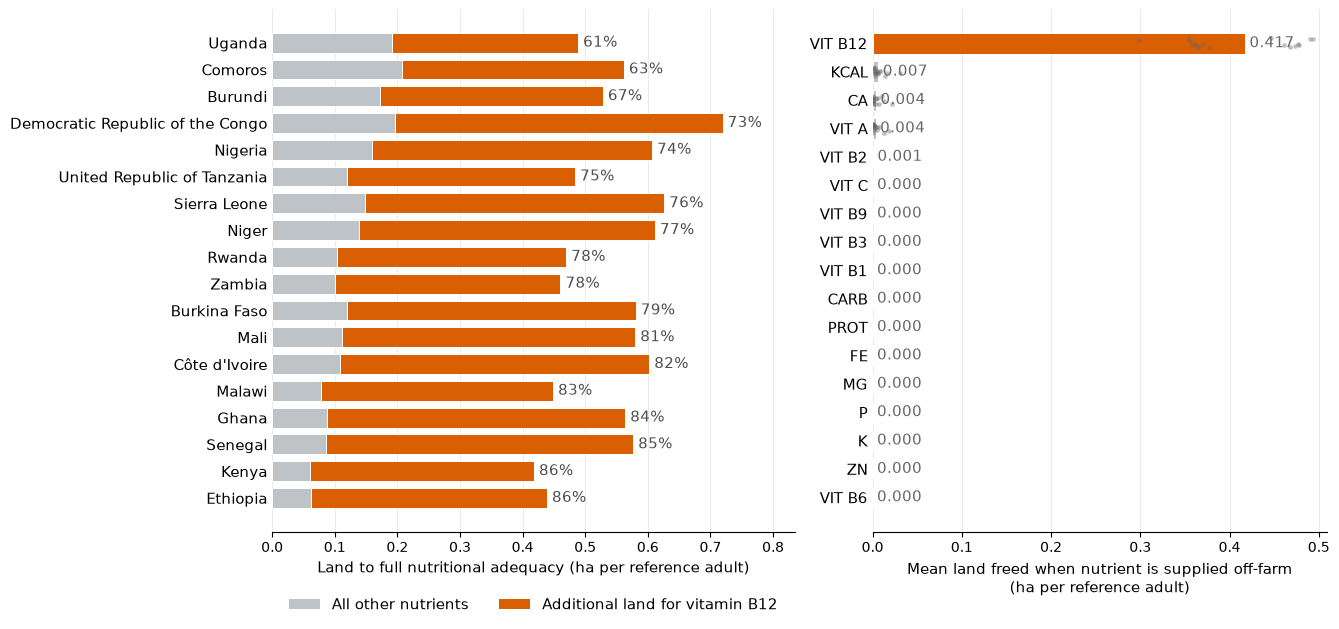

In [5]:
C_B12, C_OTHER = "#d95f02", "#bdc3c7"
DOT_MIN = 0.001

d = df_audit.copy()
d["land_other"] = d["land_b12_supplied"]
d["land_b12_add"] = d["land_full"] - d["land_b12_supplied"]
d = d.sort_values("b12_share_%", ascending=True)

fig, (axL, axR) = plt.subplots(1, 2, figsize=(13.5, 6.4), gridspec_kw={"width_ratios": [1.15, 1.0]})
fig.set_facecolor("white")
for ax in (axL, axR):
    ax.set_facecolor("white")

yL = np.arange(len(d))
axL.barh(yL, d["land_other"], color=C_OTHER, height=0.74, edgecolor="white", linewidth=0.7)
axL.barh(yL, d["land_b12_add"], left=d["land_other"], color=C_B12, height=0.74, edgecolor="white", linewidth=0.7)
for yi, (_, r) in zip(yL, d.iterrows()):
    axL.text(r["land_full"] + 0.008, yi, f"{r['b12_share_%']:.0f}%", va="center", ha="left", fontsize=11, color="0.30")
axL.set_yticks(yL); axL.set_yticklabels(d["country"], fontsize=11)
axL.invert_yaxis()
axL.set_xlim(0, d["land_full"].max() * 1.16)
axL.set_xlabel("Land to full nutritional adequacy (ha per reference adult)", fontsize=11)
axL.grid(True, axis="x", color="0.90", lw=0.6); axL.set_axisbelow(True)
for s in ("top", "right", "left"):
    axL.spines[s].set_visible(False)
axL.tick_params(axis="y", length=0)
axL.legend(handles=[Patch(facecolor=C_OTHER, label="All other nutrients"),
                    Patch(facecolor=C_B12, label="Additional land for vitamin B12")],
           frameon=False, fontsize=11, loc="upper center", bbox_to_anchor=(0.5, -0.10), ncol=2)

yR = np.arange(len(order))
vals = [mean_freed[n] for n in order]
cols = [C_B12 if n == "vit.b12" else C_OTHER for n in order]
axR.barh(yR, vals, color=cols, height=0.74, edgecolor="white", linewidth=0.7)
rng = np.random.default_rng(0)
for yi, n in zip(yR, order):
    if mean_freed[n] >= DOT_MIN:
        xs = np.clip(list(freed[n].values()), 0, None)
        axR.scatter(xs, yi + rng.uniform(-0.17, 0.17, size=len(xs)), s=11, color="0.40", alpha=0.40, linewidth=0, zorder=3)
xmax = max(vals)
for yi, n in zip(yR, order):
    axR.text(mean_freed[n] + xmax * 0.012, yi, f"{mean_freed[n]:.3f}", va="center", ha="left", fontsize=11, color="0.40")
axR.set_yticks(yR); axR.set_yticklabels([n.upper().replace("VIT.", "VIT ") for n in order], fontsize=11)
axR.invert_yaxis()
axR.set_xlim(0, xmax * 1.22)
axR.set_xlabel("Mean land freed when nutrient is supplied off-farm\n(ha per reference adult)", fontsize=11)
axR.grid(True, axis="x", color="0.90", lw=0.6); axR.set_axisbelow(True)
for s in ("top", "right", "left"):
    axR.spines[s].set_visible(False)
axR.tick_params(axis="y", length=0)

fig.tight_layout()
fig.subplots_adjust(bottom=0.16)
plt.show()

## Notes

- No independent precomputed ground-truth file exists for this figure the
  way `country_mar_wlc.csv` does for Figure 2, so this notebook's numbers
  are the primary check on the methodology, not a comparison against a
  separately-generated reference.
- For interactive exploration - including a per-country drill-down into
  which specific products drive the B12 land cost - see the companion
  dashboard: **[dashboard](https://foodsec-dashboard.politerock-163c694a.switzerlandnorth.azurecontainerapps.io)**
